# IS630: Green Light for an Indie Studio
## Notebook 05: AQ4, How Do We Translate These Insights into Decisions a Business Can Make?
**Group**: [Insert names]

> **AI Coding Assistant Declaration**:
> An AI coding assistant wrote the code in this notebook and drafted its method at the group's direction, including the rule for choosing case games. The group must review and accept it before submission. Every code section is labelled as AI-generated. The notebook produces predictions, tables and figures for real games only. All recommendations, interpretations and conclusions are written by group members in the designated cells.

**AQ4** (group wording): *How do we translate these actionable insights into decisions that a business can make? For example, are there markets that are more important to user scores?*

AQ4 is answered through case studies. The AQ2 and AQ3 models are applied to real games, to show what the model would have told a studio about each one, how close it came, and which controllable choices drove the prediction.

| Section | Content |
|---|---|
| 1 | Choosing the cases, by a rule fixed in advance |
| 2 | Case cards: observed against predicted |
| 3 | Why the model predicted that: contributions per factor |
| 4 | What-if: one controllable lever at a time on each real game |

**Two models, two views.** Both are refitted through `src/is630/models.py` with notebook 03's priors and seed.
- **Full model** (notebook 03, Bayesian): every predictor, plus the developer's effect when the developer appears in training. How well the model describes a game with everything known.
- **Controllable model** (notebook 04's reduced model): the controllable predictors notebook 04 kept, developer effect set to zero. The prediction a new studio could make before launch from the choices it controls.

**Which games.** Cases come from the validation set, which no model was fitted on. The test holdout from notebook 00 is never loaded. A title the group names that sits in the training set is shown but marked in-sample.

**Reads:** `data/processed/02_train.parquet`, `data/processed/02_validation.parquet`, `data/processed/02_feature_spec.json`, `data/interim/04_aq3_importance.parquet`, `outputs/tables/03_aq2_bayes_summary.csv`
**Writes:** `data/interim/05_aq4_cases.parquet`, tables `outputs/tables/05_aq4_*.csv`, figures `outputs/figures/05_aq4_*.png`

**Limits that apply to every result:** cases illustrate, they do not measure accuracy; overall accuracy is notebook 03's validation table. The cases picked for being least accurate are misses by construction, and show where the model fails, not how often. Effects are associations among existing story-driven games, not the effect of adding a feature. Price is the price at scrape time, and SteamSpy's median playtime is an estimate with no sample size behind it. The "markets" example in the AQ4 wording is not covered here: it needs per-language flags built in notebook 02.

## Setup
*Code: Generated by AI Assistant*

*Written by AI Assistant*: refits both models. The full model's posterior means are compared with the table notebook 03 saved, as a check that the two notebooks describe the same fit. The controllable model's predictors are read from notebook 04's output, so the two notebooks cannot disagree on which factors count.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()) / "src"))
from is630 import config
from is630.clean import normalise_title
from is630.models import COMPLETION_PRIORS, SAMPLE_KW, completion_model, completion_sample

for d in (config.FIGURES, config.TABLES):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
rng = np.random.default_rng(config.SEED)

def save_fig(fig, name):
    # Write a figure to outputs/figures at 300 dpi.
    fig.savefig(config.FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")

df_train = pd.read_parquet(config.PROCESSED / "02_train.parquet")
df_val = pd.read_parquet(config.PROCESSED / "02_validation.parquet")
with open(config.PROCESSED / "02_feature_spec.json", encoding="utf-8") as f:
    FEATURES = json.load(f)["model_features"]
s = completion_sample(df_train, df_val, FEATURES)
print(f"rows in: {len(df_train):,} / {len(df_val):,}; completion model sample: {len(s.y_train):,} train, {len(s.y_val):,} validation")

imp = pd.read_parquet(config.INTERIM / "04_aq3_importance.parquet").set_index("feature")
CONTROL = [f for f in FEATURES if imp.loc[f, "in_reduced_model"]]
LABEL = imp["label"].to_dict()
assert CONTROL, "notebook 04 kept no controllable predictors"
COLS = {"full": FEATURES, "controllable": CONTROL}
print(f"controllable model predictors ({len(CONTROL)}): {[LABEL[f] for f in CONTROL]}")

fits = {}
for name, cols in COLS.items():
    with completion_model(s.X_train[cols], s.y_train, s.dev_train, s.inv_polls_train, len(s.dev_levels), COMPLETION_PRIORS):
        fits[name] = pm.sample(**SAMPLE_KW)
    summ = az.summary(fits[name], var_names=["intercept", "beta", "sigma", "tau", "sigma_dev"])
    div = int(np.asarray(fits[name].sample_stats["diverging"]).sum())
    ok = summ["r_hat"].max() < 1.01 and summ["ess_bulk"].min() > 400 and summ["ess_tail"].min() > 400 and div == 0
    print(f"{name}: max r_hat {summ['r_hat'].max():.3f}, min ess_bulk {summ['ess_bulk'].min():.0f}, divergences {div} -> "
          f"{'converged' if ok else 'NOT CONVERGED'}")
    if name == "full":
        saved = pd.read_csv(config.TABLES / "03_aq2_bayes_summary.csv", index_col=0)
        print(f"  largest difference from notebook 03's posterior means: {(summ['mean'] - saved.loc[summ.index, 'mean']).abs().max():.4f}")

def flat(trace, name):
    # Posterior draws with chains stacked: (draws, values).
    a = np.asarray(trace.posterior[name])
    return a.reshape(a.shape[0] * a.shape[1], -1)

D = {name: {k: flat(tr, k) for k in ["intercept", "beta", "sigma", "tau", "sigma_dev", "z_dev"]} for name, tr in fits.items()}
dev_index = {d: i for i, d in enumerate(s.dev_levels)}

def predict(name, frame):
    # Draws of the typical log ratio (mu) and of a single game's log ratio, at each game's own poll count.
    d = D[name]
    mu = d["intercept"] + d["beta"] @ s.design(frame)[COLS[name]].to_numpy().T
    if name == "full":
        dev = frame["developer_group"].map(dev_index).fillna(-1).astype(int).to_numpy()
        u = d["sigma_dev"] * d["z_dev"]
        mu = mu + np.where(dev >= 0, u[:, np.clip(dev, 0, None)], 0.0)
    noise = np.sqrt(d["sigma"] ** 2 + d["tau"] ** 2 / frame["hltb_main_story_polled"].to_numpy(dtype=float)[None, :])
    return mu, mu + rng.standard_normal(mu.shape) * noise

g++ not available, if using conda: `conda install gxx`


NUTS[numpyro]: [intercept, beta, sigma_dev, z_dev, sigma, tau]


rows in: 4,224 / 1,057; completion model sample: 1,927 train, 482 validation
controllable model predictors (16): ['achievements (log)', 'has achievements', 'multiplayer', 'co-op', 'controller support', 'Steam Cloud', 'trading cards', 'VR', 'genre: indie', 'genre: casual', 'genre: action', 'genre: adventure', 'genre: simulation', 'genre: strategy', 'genre: rpg', 'genre: early access']


C:\Users\leesi\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NUTS[numpyro]: [intercept, beta, sigma_dev, z_dev, sigma, tau]


full: max r_hat 1.004, min ess_bulk 941, divergences 0 -> converged
  largest difference from notebook 03's posterior means: 0.0000


controllable: max r_hat 1.008, min ess_bulk 788, divergences 0 -> converged


## 1. Choosing the cases
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the rule is fixed before any prediction is looked at, so the cases are not picked to flatter the model. In order, skipping games already picked:

- the 3 validation games with the most Steam reviews, as recognisable titles;
- the 3 most-reviewed validation games that are tagged indie or self-published, closer to what the studio would build;
- by the controllable model's absolute error on the log ratio: the 3 most accurate, the 3 least accurate, and the 3 closest to the median error;
- any titles in `NAMED_TITLES`, matched by normalised title. The list is empty until the group fills it. A named game in the training set is marked in-sample.

In [2]:
NAMED_TITLES = []   # group to fill, for example ["Title One", "Title Two"]

mu_val, _ = predict("controllable", s.val)
pool = s.val.assign(abs_error=np.abs(s.y_val - mu_val.mean(0)))
picked = []

def take(frame, reason, n, split="validation"):
    seen = {p["steam_appid"] for p in picked}
    for appid in frame.loc[~frame["steam_appid"].isin(seen), "steam_appid"].head(n):
        picked.append({"steam_appid": appid, "reason": reason, "split": split})

by_reviews = pool.sort_values("steam_review_count", ascending=False)
take(by_reviews, "most reviewed", 3)
take(by_reviews[(by_reviews["genre_indie"] == 1) | (by_reviews["flag_self_published"] == 1)], "most reviewed, indie or self-published", 3)
take(pool.sort_values("abs_error"), "most accurate", 3)
take(pool.sort_values("abs_error", ascending=False), "least accurate", 3)
take(pool.iloc[(pool["abs_error"] - pool["abs_error"].median()).abs().argsort()], "median error", 3)
for title in NAMED_TITLES:
    key = normalise_title(pd.Series([title])).iloc[0]
    for frame, split in [(s.val, "validation"), (s.train, "training (in-sample)")]:
        hit = frame[normalise_title(frame["steam_name"]) == key]
        if len(hit):
            take(hit, "named by the group", 1, split)
            break
    else:
        print(f"not in the completion model sample: {title}")

case_list = pd.DataFrame(picked)
frames = pd.concat([s.val.assign(split="validation"), s.train.assign(split="training (in-sample)")])
cases = case_list.merge(frames.drop(columns="split"), on="steam_appid", how="left")
assert len(cases) == len(case_list)
case_list.assign(steam_name=cases["steam_name"]).to_csv(config.TABLES / "05_aq4_case_list.csv", index=False)
print(f"rows out: {len(cases)} cases")
cases[["steam_name", "reason", "split", "steam_review_count"]]

rows out: 15 cases


,steam_name,reason,split,steam_review_count
0,Black Myth: Wukong,most reviewed,validation,1150098
1,DARK SOULS™ III,most reviewed,validation,413775
2,Fallout 4,most reviewed,validation,392287
3,Mirror,"most reviewed, indie or self-published",validation,82973
4,Getting Over It with Bennett Foddy,"most reviewed, indie or self-published",validation,77003
5,Hitman: Absolution™,"most reviewed, indie or self-published",validation,55701
6,Kelvin and the Infamous Machine,most accurate,validation,957
7,The Planet Crafter,most accurate,validation,54316
8,The Gallery - Episode 2: Heart of the Emberstone,most accurate,validation,401
9,Nancy Drew®: Labyrinth of Lies,least accurate,validation,100


## 2. Case cards
*Code: Generated by AI Assistant*

*Written by AI Assistant*: for each case, what was observed and what each model predicted. `typical` is the posterior median of the typical ratio for a game with these characteristics, with its 90% credible interval. The 90% single-game interval adds game-to-game noise and the HowLongToBeat poll noise at that game's own poll count, so it is the range the observed ratio should fall in. `inside` says whether it did.

In [3]:
card = pd.DataFrame({
    "game": cases["steam_name"].to_numpy(), "reason": cases["reason"].to_numpy(), "split": cases["split"].to_numpy(),
    "reviews": cases["steam_review_count"].to_numpy(), "positive_rate": cases["steam_positive_rate"].round(3).to_numpy(),
    "median_playtime_h": (cases["steam_median_playtime_forever"] / 60).round(1).to_numpy(),
    "main_story_h": cases["hltb_main_story"].round(1).to_numpy(), "polls": cases["hltb_main_story_polled"].astype(int).to_numpy(),
    "observed_ratio": cases["completion_ratio"].round(3).to_numpy(),
})
draws = {}
for name in COLS:
    mu, single = predict(name, cases)
    draws[name] = (mu, single)
    card[f"{name}_typical"] = np.exp(np.median(mu, 0))
    card[f"{name}_cred_5%"], card[f"{name}_cred_95%"] = np.exp(np.quantile(mu, [0.05, 0.95], axis=0))
    card[f"{name}_single_5%"], card[f"{name}_single_95%"] = np.exp(np.quantile(single, [0.05, 0.95], axis=0))
    card[f"{name}_inside"] = card["observed_ratio"].between(card[f"{name}_single_5%"], card[f"{name}_single_95%"])
card.to_csv(config.TABLES / "05_aq4_cases.csv", index=False)
print("observed ratio inside the 90% single-game interval:",
      {name: f"{int(card[f'{name}_inside'].sum())} of {len(card)}" for name in COLS})
card.round(3)

observed ratio inside the 90% single-game interval: {'full': '11 of 15', 'controllable': '10 of 15'}


,game,reason,split,reviews,positive_rate,median_playtime_h,main_story_h,polls,observed_ratio,full_typical,...,full_cred_95%,full_single_5%,full_single_95%,full_inside,controllable_typical,controllable_cred_5%,controllable_cred_95%,controllable_single_5%,controllable_single_95%,controllable_inside
0,Black Myth: Wukong,most reviewed,validation,1150098,0.967,46.9,38.2,250,1.228,0.571,...,0.687,0.226,1.434,True,0.436,0.389,0.487,0.157,1.192,False
1,DARK SOULS™ III,most reviewed,validation,413775,0.943,39.4,31.2,1855,1.265,0.573,...,0.737,0.232,1.426,True,0.693,0.589,0.817,0.261,1.740,True
2,Fallout 4,most reviewed,validation,392287,0.831,30.5,27.8,849,1.097,0.416,...,0.596,0.162,1.076,False,0.400,0.350,0.459,0.161,1.064,False
3,Mirror,"most reviewed, indie or self-published",validation,82973,0.969,5.3,6.2,50,0.848,0.483,...,0.594,0.150,1.493,True,0.607,0.522,0.705,0.186,1.972,True
4,Getting Over It with Bennett Foddy,"most reviewed, indie or self-published",validation,77003,0.824,1.9,6.3,305,0.305,0.732,...,0.910,0.290,1.842,True,0.686,0.575,0.818,0.257,1.843,True
5,Hitman: Absolution™,"most reviewed, indie or self-published",validation,55701,0.929,7.6,12.3,939,0.616,0.296,...,0.525,0.104,0.864,True,0.583,0.524,0.651,0.233,1.593,True
6,Kelvin and the Infamous Machine,most accurate,validation,957,0.905,4.5,4.2,33,1.074,0.850,...,1.499,0.208,3.290,True,1.071,0.960,1.194,0.284,3.714,True
7,The Planet Crafter,most accurate,validation,54316,0.960,22.9,34.3,38,0.667,0.699,...,0.855,0.215,2.393,True,0.670,0.564,0.792,0.193,2.291,True
8,The Gallery - Episode 2: Heart of the Emberstone,most accurate,validation,401,0.833,3.0,3.1,8,0.982,1.032,...,1.876,0.132,8.431,True,0.974,0.759,1.260,0.126,7.269,True
9,Nancy Drew®: Labyrinth of Lies,least accurate,validation,100,0.730,0.0,5.0,5,0.003,1.584,...,2.274,0.140,17.006,False,0.482,0.425,0.547,0.046,5.279,False


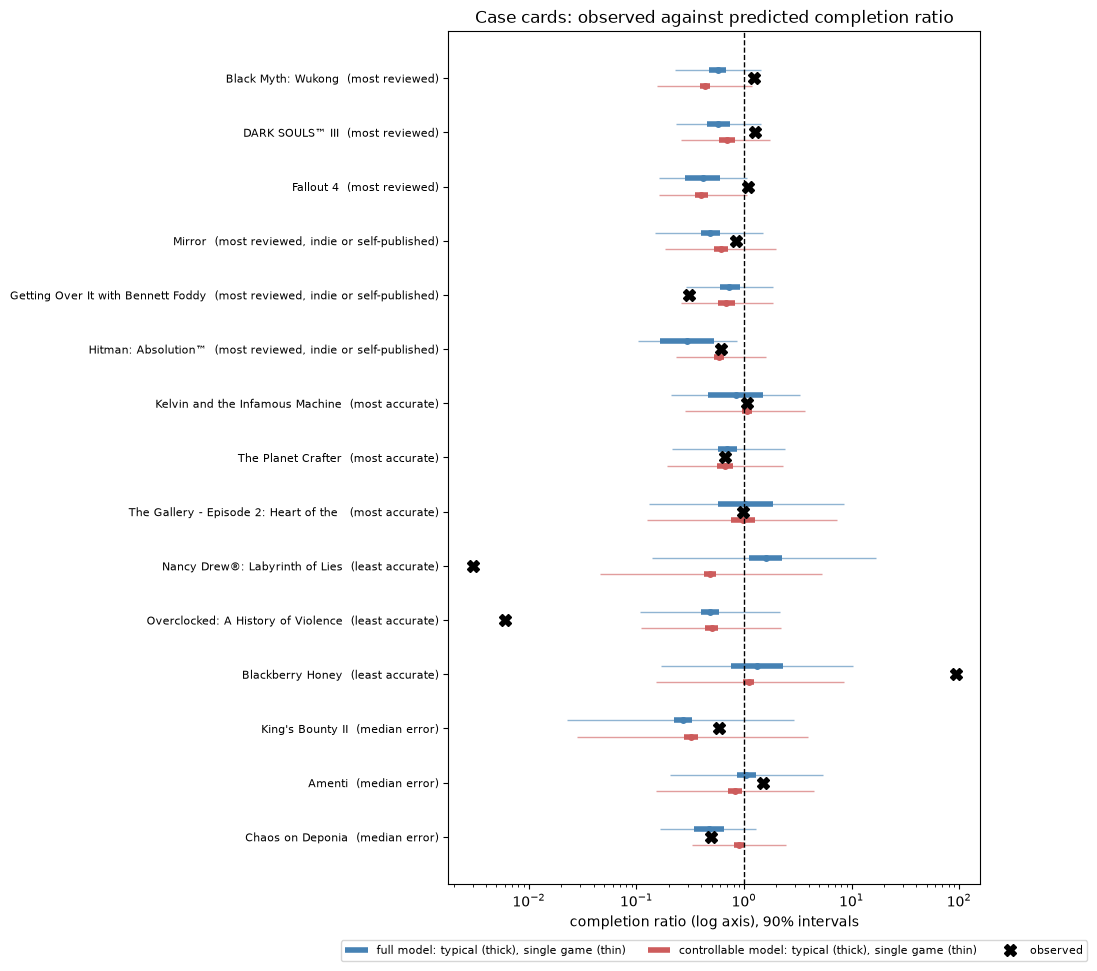

In [4]:
fig, ax = plt.subplots(figsize=(10, 0.55 * len(card) + 1.5))
y = np.arange(len(card))[::-1]
for name, off, colour in [("full", 0.15, "steelblue"), ("controllable", -0.15, "indianred")]:
    ax.hlines(y + off, card[f"{name}_single_5%"], card[f"{name}_single_95%"], color=colour, linewidth=1, alpha=0.6)
    ax.hlines(y + off, card[f"{name}_cred_5%"], card[f"{name}_cred_95%"], color=colour, linewidth=4,
              label=f"{name} model: typical (thick), single game (thin)")
    ax.plot(card[f"{name}_typical"], y + off, "o", color=colour, markersize=4)
ax.plot(card["observed_ratio"], y, "kX", markersize=8, label="observed")
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yticks(y); ax.set_yticklabels([f"{g[:38]}  ({r})" for g, r in zip(card["game"], card["reason"])], fontsize=8)
ax.set_xlabel("completion ratio (log axis), 90% intervals")
ax.set_title("Case cards: observed against predicted completion ratio")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=3)
plt.tight_layout()
save_fig(fig, "05_aq4_case_cards")
plt.show()

### Interpretation: Case cards
**Author**: 
<!-- For each group of cases, describe how the observed ratio compares with each model's prediction and whether it falls inside the single-game interval. Compare the full and controllable models: how much the prediction changes once the developer and the uncontrollable factors are known. Comment on how wide the single-game intervals are and what that width means for a studio planning one game. -->

## 3. Why the model predicted that
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the controllable model's prediction is a sum on the log scale, so it splits exactly into one contribution per predictor, measured against a reference game: every controllable predictor at its training mean (continuous) or most common value (binary). Each contribution is a multiplier on the ratio. The waterfall starts at the reference game's ratio, applies the five largest contributions and then the rest together, and ends at the prediction. The black line is the observed ratio. The gap between prediction and observation is the part the controllable factors do not explain. Posterior means are used, so the bars carry no intervals.

In [5]:
b_mean = D["controllable"]["beta"].mean(0)
a_mean = float(D["controllable"]["intercept"].mean())
x_ref = pd.Series(0.0, index=CONTROL)
for f in CONTROL:
    if f in s.binary:
        x_ref[f] = float(s.train[f].mode().iloc[0])
ref_log = a_mean + b_mean @ x_ref.to_numpy()

Xc = s.design(cases)[CONTROL]
contrib = (Xc - x_ref) * b_mean                                   # cases x predictors, log scale
contrib.index = cases["steam_name"].to_numpy()
contrib_table = np.exp(contrib).rename(columns=LABEL)
contrib_table.insert(0, "reference_ratio", np.exp(ref_log))
contrib_table["predicted_ratio"] = np.exp(ref_log + contrib.sum(axis=1))
contrib_table["observed_ratio"] = cases["completion_ratio"].to_numpy()
contrib_table.to_csv(config.TABLES / "05_aq4_contributions.csv")
print(f"reference game ratio: {np.exp(ref_log):.3f}")
contrib_table.round(3)

reference game ratio: 0.920


,reference_ratio,achievements (log),has achievements,multiplayer,co-op,controller support,Steam Cloud,trading cards,VR,genre: indie,genre: casual,genre: action,genre: adventure,genre: simulation,genre: strategy,genre: rpg,genre: early access,predicted_ratio,observed_ratio
Black Myth: Wukong,0.92,0.867,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.84,1.000,0.856,1.000,1.0,1.000,0.76,1.0,0.436,1.228
DARK SOULS™ III,0.92,0.918,1.000,0.866,1.192,1.000,1.144,1.000,1.000,0.84,1.000,0.856,0.967,1.0,1.000,1.00,1.0,0.694,1.265
Fallout 4,0.92,0.864,1.000,1.000,1.000,1.000,1.000,0.816,1.000,0.84,1.000,1.000,0.967,1.0,1.000,0.76,1.0,0.400,1.097
Mirror,0.92,0.840,1.000,1.000,1.000,1.035,1.000,1.000,1.000,1.00,1.000,1.000,1.000,1.0,1.000,0.76,1.0,0.607,0.848
Getting Over It with Bennett Foddy,0.92,1.147,1.000,1.000,1.000,1.000,1.144,0.816,1.000,0.84,1.000,0.856,0.967,1.0,1.000,1.00,1.0,0.685,0.305
Hitman: Absolution™,0.92,0.911,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.84,1.000,0.856,0.967,1.0,1.000,1.00,1.0,0.583,0.616
Kelvin and the Infamous Machine,0.92,0.983,1.000,1.000,1.000,1.035,1.144,1.000,1.000,1.00,1.000,1.000,1.000,1.0,1.000,1.00,1.0,1.071,1.074
The Planet Crafter,0.92,0.898,1.000,0.866,1.192,1.000,1.144,0.816,1.000,0.84,1.000,1.000,1.000,1.0,1.000,1.00,1.0,0.668,0.667
The Gallery - Episode 2: Heart of the Emberstone,0.92,0.957,1.000,1.000,1.000,1.035,1.000,1.000,0.808,1.00,1.325,1.000,1.000,1.0,1.000,1.00,1.0,0.976,0.982
Nancy Drew®: Labyrinth of Lies,0.92,1.304,0.495,1.000,1.000,1.035,1.144,0.816,1.000,0.84,1.000,1.000,1.000,1.0,1.000,1.00,1.0,0.482,0.003


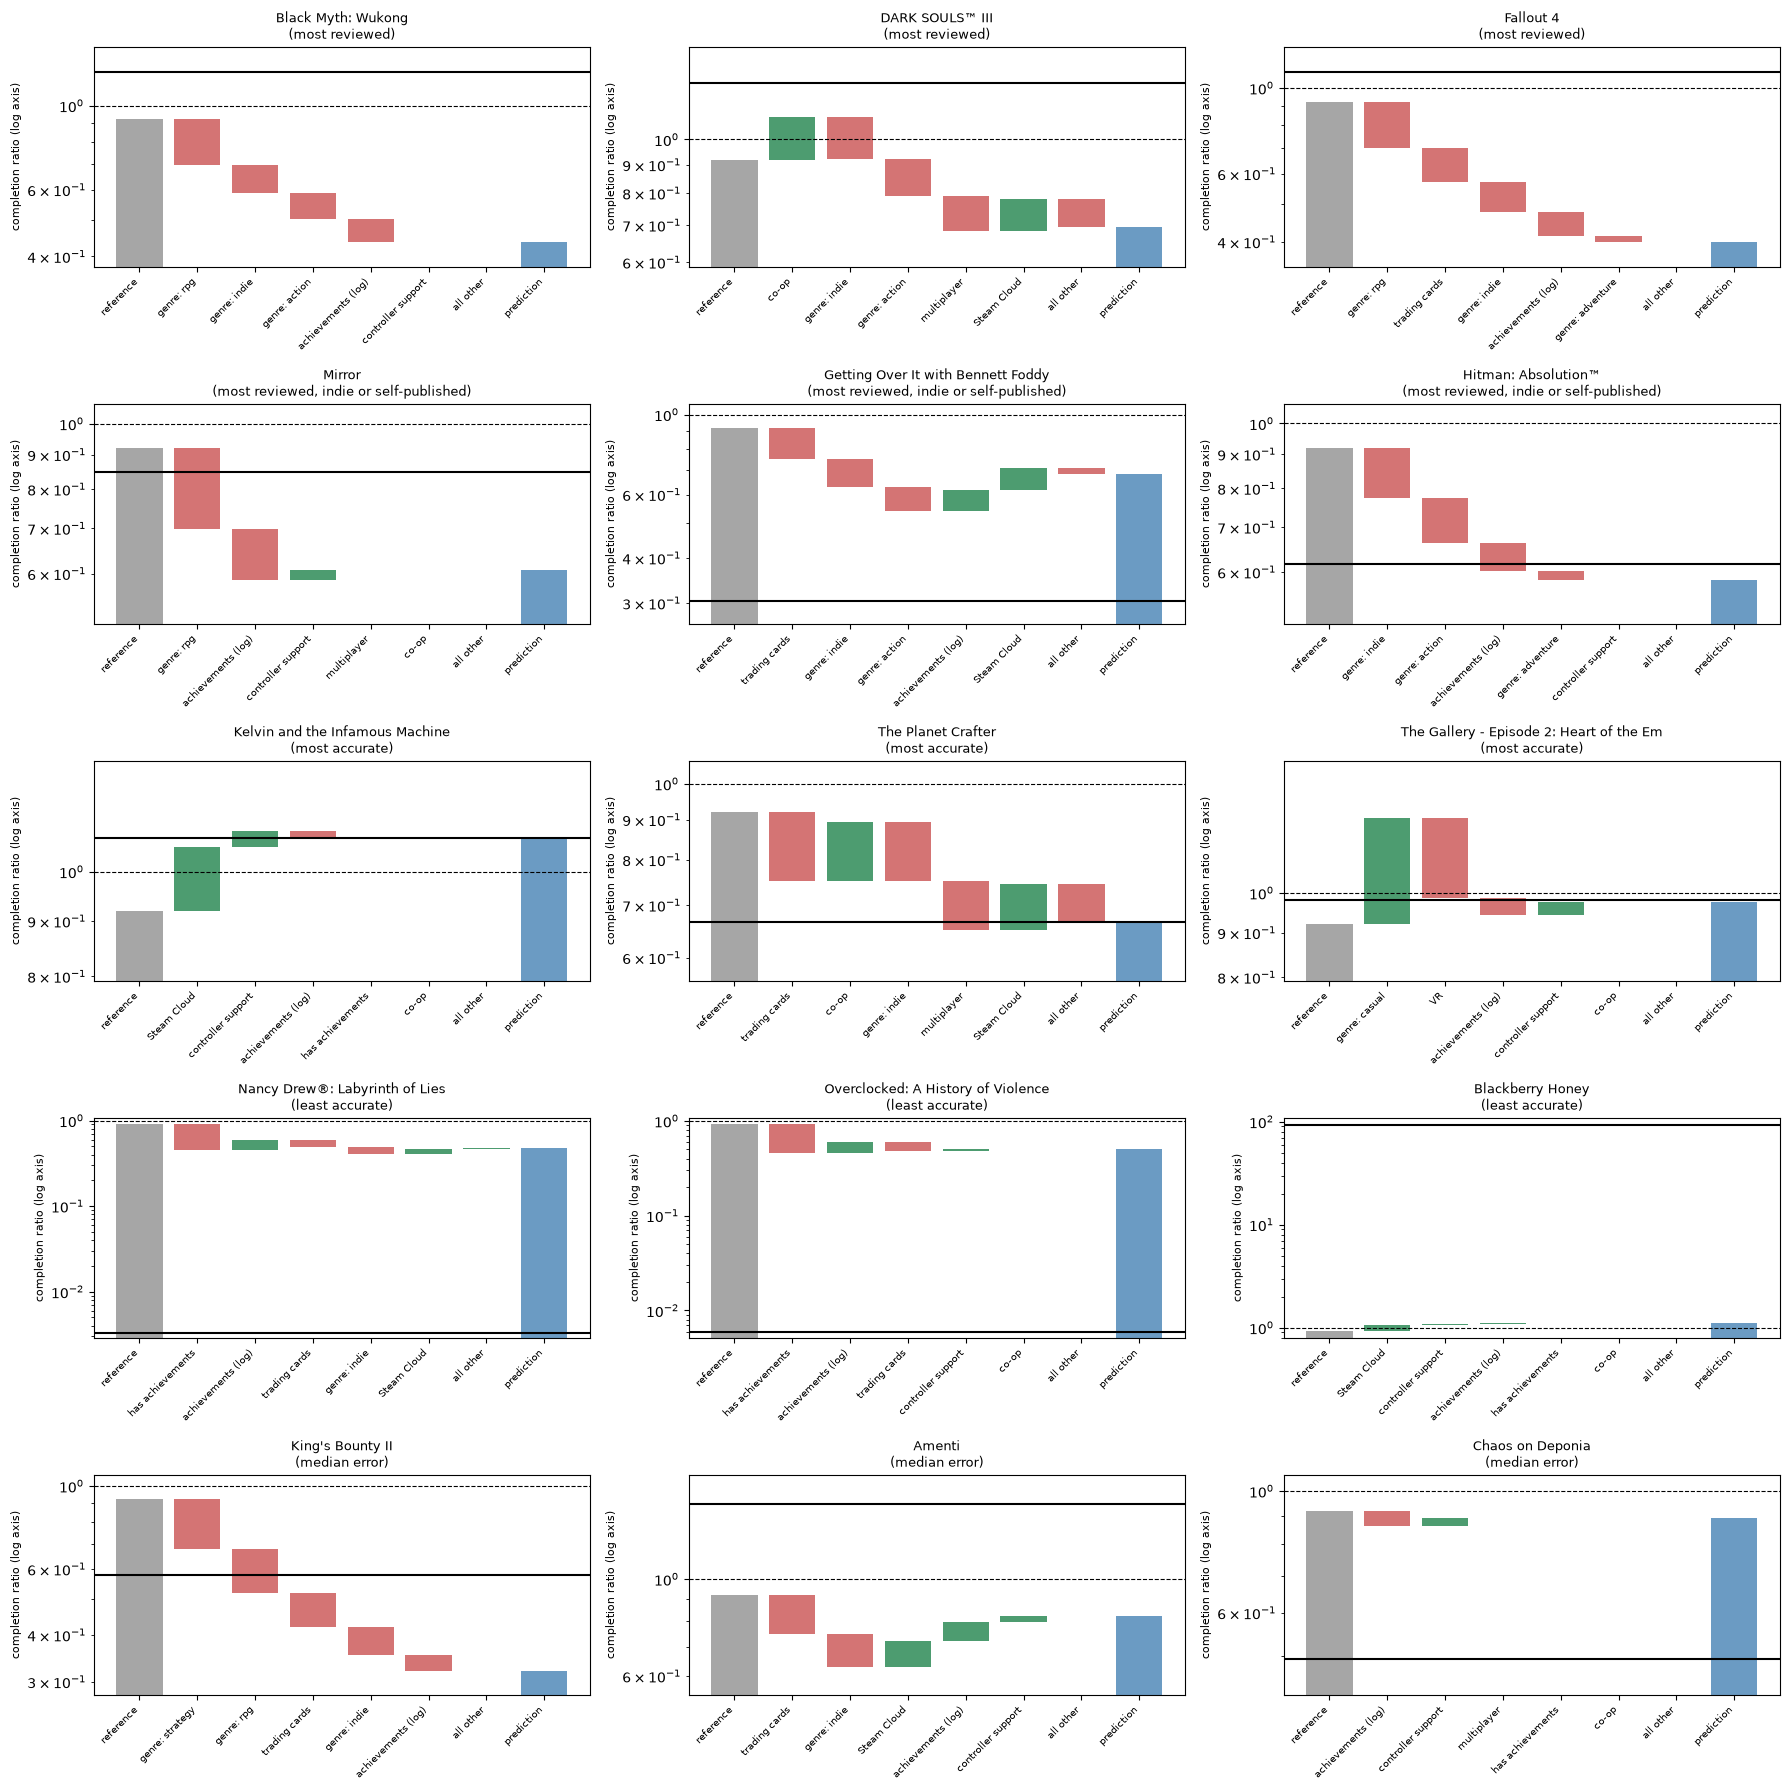

In [6]:
TOP_K = 5
ncol = 3
nrow = int(np.ceil(len(cases) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 3.6 * nrow), squeeze=False)
for ax, (game, row), obs, reason in zip(axes.ravel(), contrib.iterrows(), cases["completion_ratio"], cases["reason"]):
    top = row.reindex(row.abs().sort_values(ascending=False).index)[:TOP_K]
    steps = [(LABEL[f], v) for f, v in top.items()] + [("all other", row.drop(top.index).sum())]
    levels = ref_log + np.cumsum([0] + [v for _, v in steps])
    floor = np.exp(min(levels.min(), np.log(obs)) - 0.15)
    ceil = np.exp(max(levels.max(), np.log(obs)) + 0.15)
    level = ref_log
    ax.bar(0, np.exp(level) - floor, bottom=floor, color="grey", alpha=0.7)
    for i, (name, v) in enumerate(steps, start=1):
        lo, hi = sorted([np.exp(level), np.exp(level + v)])
        ax.bar(i, hi - lo, bottom=lo, color="seagreen" if v > 0 else "indianred", alpha=0.85)
        level += v
    ax.bar(len(steps) + 1, np.exp(level) - floor, bottom=floor, color="steelblue", alpha=0.8)
    ax.axhline(obs, color="black", linewidth=1.5)
    ax.axhline(1, color="black", linestyle="--", linewidth=0.8)
    ax.set_yscale("log")
    ax.set_ylim(floor, ceil)
    ax.set_xticks(range(len(steps) + 2))
    ax.set_xticklabels(["reference"] + [n for n, _ in steps] + ["prediction"], rotation=45, ha="right", fontsize=7)
    ax.set_title(f"{game[:40]}\n({reason})", fontsize=9)
    ax.set_ylabel("completion ratio (log axis)", fontsize=8)
for ax in axes.ravel()[len(cases):]:
    ax.set_visible(False)
plt.tight_layout()
save_fig(fig, "05_aq4_waterfalls")
plt.show()

### Interpretation: Why the model predicted that
**Author**: 
<!-- For a few contrasting cases, say which controllable choices pushed the prediction up or down and by how much, and how far the prediction then sits from the observed ratio. For the least accurate cases, describe what the model could not see: what about those games might explain the gap, using the observed playtime and main-story hours on the case cards. -->

## 4. What-if on real games
*Code: Generated by AI Assistant*

*Written by AI Assistant*: for each case, one controllable lever is changed at a time and the controllable model's predicted multiplier on the ratio is reported, with its 90% credible interval and the probability that the change raises the ratio. Binary levers are switched to the other value. Achievements are one lever with three settings, none, and the 25th and 75th percentile of training games that have achievements, so the achievements flag and count always agree. Any other continuous lever moves to its 25th and 75th training percentiles.

These multipliers apply notebook 04's associations to concrete games. They describe how games that differ in this way differ in completion ratio, not what would happen if this game changed.

In [7]:
B = D["controllable"]["beta"]
col = {f: i for i, f in enumerate(CONTROL)}
ACH = ("flag_has_achievements", "feature_log_achievements")
z_of = lambda f, raw: (np.log1p(raw) - s.centre[f]) / s.scale[f]

settings = []                                                      # (lever, setting label, {column: new standardised value})
for f in CONTROL:
    if f in ACH:
        continue
    if f in s.binary:
        settings.append((LABEL[f], "switch", None, f))
    else:
        for q in (0.25, 0.75):
            settings.append((LABEL[f], f"{int(q * 100)}th percentile", {f: float(s.X_train[f].quantile(q))}, None))
if all(f in CONTROL for f in ACH):
    with_ach = s.train.loc[s.train["steam_achievements"] > 0, "steam_achievements"]
    settings.append(("achievements", "none", {ACH[0]: 0.0, ACH[1]: z_of(ACH[1], 0)}, None))
    for q in (0.25, 0.75):
        k = float(with_ach.quantile(q))
        settings.append(("achievements", f"{k:.0f} (p{int(q * 100)} of games with any)", {ACH[0]: 1.0, ACH[1]: z_of(ACH[1], k)}, None))

rows = []
for game, x in zip(cases["steam_name"], Xc.to_dict("records")):
    for lever, label, update, flip in settings:
        if flip is not None:
            update = {flip: 1.0 - x[flip]}
            label = "off to on" if x[flip] == 0 else "on to off"
        delta = sum(B[:, col[f]] * (v - x[f]) for f, v in update.items())
        if np.allclose(delta, 0):
            continue
        m = np.exp(delta)
        rows.append({"game": game, "lever": lever, "change": label, "median_multiplier": np.median(m),
                     "multiplier_5%": np.quantile(m, 0.05), "multiplier_95%": np.quantile(m, 0.95), "p_raises_ratio": (delta > 0).mean()})
what_if = pd.DataFrame(rows)
what_if.to_csv(config.TABLES / "05_aq4_what_if.csv", index=False)
print(f"{len(what_if)} what-if rows for {what_if['game'].nunique()} games")
what_if.pivot_table(index="game", columns="lever", values="median_multiplier", aggfunc="first").round(2)

252 what-if rows for 15 games


lever,Steam Cloud,VR,achievements,co-op,controller support,genre: action,genre: adventure,genre: casual,genre: early access,genre: indie,genre: rpg,genre: simulation,genre: strategy,multiplayer,trading cards
game,,,,,,,,,,,,,,,
Amenti,0.87,0.81,0.58,1.19,0.97,0.86,0.97,1.33,1.49,1.19,0.76,1.15,0.74,0.86,1.23
Black Myth: Wukong,1.14,0.81,0.74,1.19,1.04,1.17,0.97,1.33,1.49,1.19,1.32,1.15,0.74,0.86,0.82
Blackberry Honey,0.87,0.81,0.64,1.19,0.97,0.86,0.97,1.33,1.49,0.84,0.76,1.15,0.74,0.86,0.82
Chaos on Deponia,1.14,0.81,0.69,1.19,0.97,0.86,0.97,1.33,1.49,0.84,0.76,1.15,0.74,0.86,0.82
DARK SOULS™ III,0.87,0.81,0.70,0.84,1.04,1.17,1.04,1.33,1.49,1.19,0.76,1.15,0.74,1.16,0.82
Fallout 4,1.14,0.81,0.75,1.19,1.04,0.86,1.04,1.33,1.49,1.19,1.32,1.15,0.74,0.86,1.23
Getting Over It with Bennett Foddy,0.87,0.81,0.56,1.19,1.04,1.17,1.04,1.33,1.49,1.19,0.76,1.15,0.74,0.86,1.23
Hitman: Absolution™,1.14,0.81,0.71,1.19,1.04,1.17,1.04,1.33,1.49,1.19,0.76,1.15,0.74,0.86,0.82
Kelvin and the Infamous Machine,0.87,0.81,0.66,1.19,0.97,0.86,0.97,1.33,1.49,0.84,0.76,1.15,0.74,0.86,0.82


### Interpretation: What-if on real games
**Author**: 
<!-- Pick a few cases and describe which single lever is associated with the largest change in completion ratio for that game, how sure the model is (the credible interval and the probability of raising the ratio), and whether the same lever matters for every game. Keep the associational caveat beside every statement. The business recommendations that follow from the cases go in the conclusion below. -->

## Conclusion: from cases to decisions
**Author**:
<!-- This is the answer to AQ4, written by the group. Using the case cards, the waterfalls and the what-if table, say what a small studio can and cannot take from these models when planning a story-driven game: which controllable choices the evidence supports, how much uncertainty surrounds any single game's outcome, and where the model is likely to be wrong. Recommendations belong here and must be the group's own. -->

## Save for later stages
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the case list with both models' predictions, for the report and slides.

In [8]:
cases_out = case_list.join(card.drop(columns=["reason", "split"]))
cases_out.to_parquet(config.INTERIM / "05_aq4_cases.parquet", index=False)
print(f"rows out: {len(cases_out)} cases -> data/interim/05_aq4_cases.parquet")
print(f"figures: {sorted(p.name for p in config.FIGURES.glob('05_aq4_*.png'))}")
print(f"tables : {sorted(p.name for p in config.TABLES.glob('05_aq4_*.csv'))}")

rows out: 15 cases -> data/interim/05_aq4_cases.parquet
figures: ['05_aq4_case_cards.png', '05_aq4_waterfalls.png']
tables : ['05_aq4_case_list.csv', '05_aq4_cases.csv', '05_aq4_contributions.csv', '05_aq4_what_if.csv']
